# 2. Modelagem

Neste notebook vamos:

1. Separar treino e teste respeitando o tempo
2. Escolher a métrica certa para um problema desbalanceado
3. Criar linhas de base (o mínimo que um modelo precisa superar)
4. Comparar três modelos com validação cruzada temporal
5. Ajustar os hiperparâmetros do melhor
6. Avaliar uma única vez no teste
7. Mostrar, na prática, o que o vazamento de dados faria com os resultados

In [1]:
import sys
from pathlib import Path

# Encontra a raiz do projeto e coloca a pasta src no caminho de importação.
RAIZ = Path.cwd()
while not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from olist import graficos as g

g.aplicar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

import joblib, json
from olist.dados import carregar_base, conectar
from olist import modelagem as m

base = m.preparar_tipos(carregar_base())

## 2.1 Divisão temporal entre treino e teste

Em muitos tutoriais, a divisão é aleatória: 80% para treino e 20% para teste, embaralhados. Aqui isso seria um erro, por dois motivos:

- **Em produção o modelo sempre prevê o futuro.** Ele é treinado com os pedidos que já aconteceram e usado nos próximos. A avaliação precisa imitar isso.
- **O comportamento muda no tempo** (vimos no notebook 1 os picos de atraso). Com divisão aleatória, o modelo veria pedidos de março de 2018 no treino e seria testado em outros pedidos do mesmo mês, uma situação mais fácil do que a real.

Então: **treino** com as pesquisas enviadas até maio de 2018 e **teste** com as de junho a agosto de 2018. O teste fica trancado até o final.

In [2]:
treino, teste = m.dividir_treino_teste(base)
X_treino, y_treino = treino[m.VARIAVEIS], treino[m.ALVO]
X_teste, y_teste = teste[m.VARIAVEIS], teste[m.ALVO]

pd.DataFrame({
    "período": [f"{treino.data_pesquisa.min():%m/%Y} a {treino.data_pesquisa.max():%m/%Y}",
                f"{teste.data_pesquisa.min():%m/%Y} a {teste.data_pesquisa.max():%m/%Y}"],
    "pedidos": [len(treino), len(teste)],
    "taxa negativa": [y_treino.mean(), y_teste.mean()],
    "% não entregue na pesquisa": [1 - treino.entregue_antes_pesquisa.mean(), 1 - teste.entregue_antes_pesquisa.mean()],
}, index=["treino", "teste"])

,período,pedidos,taxa negativa,% não entregue na pesquisa
treino,10/2016 a 05/2018,74974,0.135,0.089
teste,06/2018 a 08/2018,20850,0.103,0.076


O teste tem menos pedidos atrasados e uma taxa negativa menor. Isso já indica que as métricas no teste podem ser diferentes das do treino. É o mundo real: a operação logística melhorou depois do pico de março.

As variáveis usadas pelo modelo (todas conhecidas no momento do envio da pesquisa):

In [3]:
print(f"{len(m.NUMERICAS)} numéricas:", ", ".join(m.NUMERICAS))
print()
print(f"{len(m.CATEGORICAS)} categóricas:", ", ".join(m.CATEGORICAS))

25 numéricas: prazo_prometido_dias, dias_ate_postagem, entregue_antes_pesquisa, dias_atraso_observado, dias_ate_entrega, n_itens, n_produtos, n_vendedores, media_fotos, parcelas, n_pagamentos, usou_voucher, mesmo_estado, dia_semana_compra, hora_compra, vendedor_taxa_negativa_previa, horas_ate_aprovacao, valor_produtos, valor_frete, razao_frete_produtos, peso_total_g, volume_total_cm3, media_tamanho_descricao, distancia_km, vendedor_n_avaliacoes_previas

4 categóricas: categoria, tipo_pagamento, uf_cliente, uf_vendedor


## 2.2 Qual métrica usar?

Começando pelo modelo mais burro possível: **sempre prever que o pedido não vai receber avaliação negativa.**

In [4]:
from sklearn.metrics import accuracy_score
print(f"Acurácia de 'nunca é negativa' no teste: {accuracy_score(y_teste, np.zeros(len(y_teste))):.1%}")

Acurácia de 'nunca é negativa' no teste: 89.7%


Quase 90% de acurácia sem encontrar nenhuma avaliação negativa. É a **armadilha da acurácia em classes desbalanceadas**.

O que importa aqui é **ordenar** os pedidos por risco, para o time contatar primeiro os mais arriscados. As métricas certas são:

- **PR-AUC** (área sob a curva de precisão e recall), a métrica principal. Ela mede o quanto o modelo concentra as avaliações negativas no topo da lista. Um modelo aleatório tem PR-AUC igual à taxa base (cerca de 0,10 no teste), então qualquer valor deve ser comparado com isso.
  - **Precisão:** dos pedidos que o modelo apontou como risco, quantos realmente avaliaram mal.
  - **Recall:** das avaliações negativas que aconteceram, quantas o modelo encontrou.
- **ROC-AUC**, como métrica complementar. Ela é mais conhecida, mas fica otimista em classes raras, porque se beneficia de acertar os muitos negativos fáceis.
- **Brier score**, o erro quadrático médio das probabilidades (quanto menor, melhor). Ele indica se as probabilidades são confiáveis, o que importa para o limiar de custo do notebook 3.

## 2.3 Linhas de base

Antes de qualquer modelo, duas referências:

1. **Aleatório:** PR-AUC igual à taxa base.
2. **Regra de negócio:** ordenar os pedidos pelo atraso observado. É o que um analista faria sem machine learning ("ligue para quem está atrasado").

Se o modelo não superar a regra com folga, ele não se justifica.

In [5]:
linhas_de_base = pd.DataFrame({
    "aleatório (taxa base)": {"PR-AUC": y_teste.mean()},
    "regra: ordenar por atraso": m.avaliar(y_teste, teste["dias_atraso_observado"]).como_dict(),
}).T
linhas_de_base

,PR-AUC,ROC-AUC,Brier,Taxa base
aleatório (taxa base),0.103,NaN,NaN,NaN
regra: ordenar por atraso,0.225,0.580,0.115,0.103


## 2.4 Os três modelos

Cada modelo exige um pré-processamento diferente, e entender o porquê é parte importante do projeto.

**Regressão logística.** É um modelo linear: soma as variáveis com pesos e passa por uma função que devolve uma probabilidade. Por isso:

- não aceita valores nulos: usamos `SimpleImputer` (mediana) com `add_indicator=True`, que cria uma coluna avisando "este valor estava nulo", porque às vezes a ausência em si é informativa;
- é sensível à escala: usamos `StandardScaler` para deixar as variáveis com média 0 e desvio 1;
- variáveis com cauda longa (valor, peso, distância) recebem `log1p` antes, para que um pedido de R$ 13 mil não domine o modelo;
- categorias viram colunas 0/1 (`OneHotEncoder`); categorias com menos de 100 pedidos são agrupadas como "infrequentes".

**Random Forest.** Centenas de árvores de decisão, cada uma treinada numa amostra diferente dos dados e das variáveis; a previsão é a média delas. Árvores não ligam para escala, então só precisamos imputar nulos e transformar categorias em códigos numéricos (`OrdinalEncoder`). `min_samples_leaf=20` impede que as árvores decorem casos isolados (*overfitting*).

**Gradient Boosting (`HistGradientBoostingClassifier`).** Também usa árvores, mas em sequência: cada nova árvore tenta corrigir os erros das anteriores. A versão do scikit-learn trata valores nulos e colunas categóricas sozinha, sem pré-processamento. Costuma ser o melhor tipo de modelo para dados tabulares.

Tudo fica dentro de um `Pipeline`. Isso garante que o pré-processamento (por exemplo, a mediana usada na imputação) seja calculado **só com os dados de treino de cada etapa**, outra forma de evitar vazamento. O código está em `src/olist/modelagem.py`.

In [6]:
modelos = {
    "Regressão logística": m.pipeline_regressao_logistica,
    "Random Forest": m.pipeline_random_forest,
    "Gradient Boosting": m.modelo_gradient_boosting,
}
m.pipeline_regressao_logistica()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('num_log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0

## 2.5 Validação cruzada temporal

Para comparar modelos sem tocar no teste, usamos validação cruzada **dentro do treino**. Mas a validação cruzada comum (`KFold`) embaralha os dados, com o mesmo problema da divisão aleatória.

O `TimeSeriesSplit` divide o treino em blocos cronológicos e sempre valida no bloco seguinte ao que foi usado para treinar:

```
fold 1: [treino ]                           [valida]
fold 2: [treino          ]                  [valida]
fold 3: [treino                   ]         [valida]
fold 4: [treino                            ][valida]
        início de 2017  ---------------------->  maio de 2018
```

Assim cada fold simula "treinar com o passado e prever o mês seguinte". Leva cerca de 2 minutos, principalmente pelo Random Forest.

In [7]:
resultados_cv = []
for nome, fabrica in modelos.items():
    r = m.validar_cruzado(fabrica, X_treino, y_treino)
    r.insert(0, "modelo", nome)
    resultados_cv.append(r)
resultados_cv = pd.concat(resultados_cv, ignore_index=True)

# Regra de negócio nos mesmos folds, para comparação.
regra_cv = []
for fold, (_, idx_va) in enumerate(m.validacao_temporal().split(X_treino), start=1):
    regra_cv.append({"modelo": "Regra: atraso", "fold": fold,
                     **m.avaliar(y_treino.iloc[idx_va], X_treino["dias_atraso_observado"].iloc[idx_va]).como_dict()})
resultados_cv = pd.concat([resultados_cv, pd.DataFrame(regra_cv)], ignore_index=True)

resultados_cv.pivot(index="fold", columns="modelo", values="PR-AUC")

modelo,Gradient Boosting,Random Forest,Regra: atraso,Regressão logística
fold,,,,
1,0.281,0.306,0.233,0.296
2,0.471,0.491,0.416,0.503
3,0.587,0.572,0.494,0.556
4,0.537,0.553,0.442,0.516


In [8]:
resumo_cv = resultados_cv.groupby("modelo")[["PR-AUC", "ROC-AUC", "Brier"]].agg(["mean", "std"])
resumo_cv.sort_values(("PR-AUC", "mean"), ascending=False)

PR-AUC       ROC-AUC       Brier      
                      mean   std    mean   std  mean   std
modelo                                                    
Random Forest        0.480 0.121   0.775 0.050 0.092 0.008
Gradient Boosting    0.469 0.134   0.757 0.069 0.093 0.008
Regressão logística  0.468 0.117   0.766 0.056 0.093 0.009
Regra: atraso        0.396 0.113   0.673 0.061 0.119 0.014

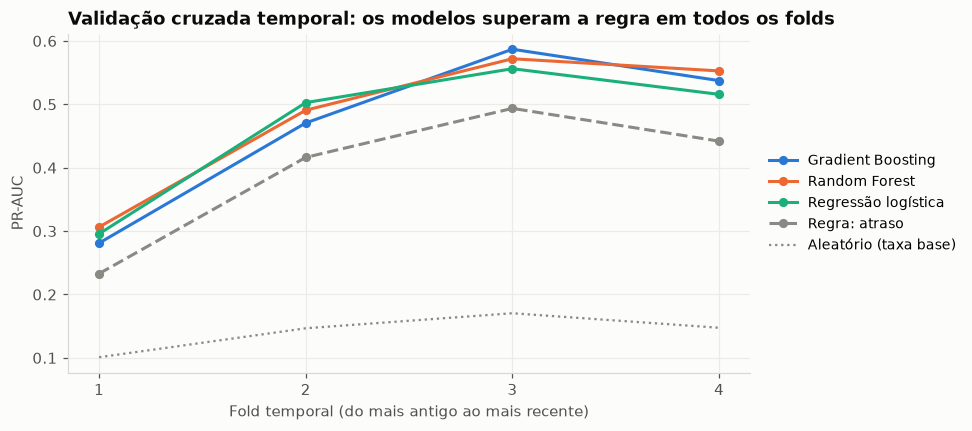

In [9]:
tabela = resultados_cv.pivot(index="fold", columns="modelo", values="PR-AUC")
taxa_fold = resultados_cv.query("modelo == 'Regra: atraso'").set_index("fold")["Taxa base"]
cores = {"Gradient Boosting": g.AZUL, "Random Forest": g.LARANJA, "Regressão logística": g.VERDE, "Regra: atraso": g.CINZA}

fig, ax = plt.subplots(figsize=(8, 4))
for nome, cor in cores.items():
    estilo = "--" if nome == "Regra: atraso" else "-"
    ax.plot(tabela.index, tabela[nome], color=cor, marker="o", markersize=5, linestyle=estilo, label=nome)
ax.plot(taxa_fold.index, taxa_fold, color=g.CINZA, linestyle=":", linewidth=1.5, label="Aleatório (taxa base)")
ax.set_xticks(tabela.index)
ax.set_xlabel("Fold temporal (do mais antigo ao mais recente)")
ax.set_ylabel("PR-AUC")
ax.set_title("Validação cruzada temporal: os modelos superam a regra em todos os folds")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
g.salvar(fig, "05_validacao_cruzada")
plt.show()

Leitura dos resultados:

- **Os três modelos superam com folga a regra de atraso** em todos os folds. O machine learning agrega valor de verdade.
- **Os três modelos ficam próximos entre si.** A diferença entre eles é menor que a variação entre um fold e outro. Na prática, o que mais pesa é a qualidade das variáveis, não o algoritmo.
- **O fold 1 é bem pior** em todos os modelos: tem pouco dado de treino e um período diferente. Isso mostra que o desempenho varia com o momento, um aviso para o teste.

Com os parâmetros padrão, o Random Forest ficou ligeiramente à frente. Mesmo assim seguimos com o **Gradient Boosting**: a diferença está dentro da variação entre folds, ele é cerca de 5 vezes mais rápido de treinar (o que permite testar mais configurações), trata nulos e categorias sozinho e, como veremos a seguir, passa o Random Forest depois de ajustado.

## 2.6 Ajuste de hiperparâmetros

Hiperparâmetros são as "configurações" do modelo, escolhidas antes do treino. Testamos combinações com a mesma validação cruzada temporal:

- `learning_rate` e `max_iter`: tamanho do passo de cada árvore e número de árvores (passos menores pedem mais árvores);
- `max_leaf_nodes`: complexidade de cada árvore;
- `min_samples_leaf`: mínimo de pedidos em cada folha, para evitar decorar casos raros.

Leva cerca de 2 minutos.

In [10]:
from itertools import product

combinacoes = [
    dict(learning_rate=lr, max_iter=it, max_leaf_nodes=folhas, min_samples_leaf=minimo)
    for (lr, it), folhas, minimo in product([(0.03, 400), (0.05, 250), (0.1, 120)], [15, 31], [50, 200])
]

busca = []
for params in combinacoes:
    r = m.validar_cruzado(lambda: m.modelo_gradient_boosting(**params), X_treino, y_treino)
    busca.append({**params, "PR-AUC médio": r["PR-AUC"].mean(), "desvio": r["PR-AUC"].std()})
busca = pd.DataFrame(busca).sort_values("PR-AUC médio", ascending=False).reset_index(drop=True)
busca

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,PR-AUC médio,desvio
0,0.030,400,15,50,0.482,0.130
1,0.050,250,15,50,0.482,0.128
2,0.050,250,15,200,0.481,0.134
3,0.100,120,15,50,0.481,0.130
4,0.030,400,15,200,0.481,0.134
5,0.100,120,15,200,0.479,0.133
6,0.030,400,31,50,0.477,0.131
7,0.050,250,31,50,0.475,0.131
8,0.050,250,31,200,0.474,0.132
9,0.030,400,31,200,0.474,0.135


In [11]:
melhores = busca.iloc[0][["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf"]].to_dict()
melhores = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in melhores.items()}
print("Melhores hiperparâmetros:", melhores)

Melhores hiperparâmetros: {'learning_rate': 0.03, 'max_iter': 400, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}


O ganho do ajuste é pequeno (de cerca de 0,47 para 0,48), e a diferença entre as melhores combinações é bem menor que o desvio entre folds. Isso é comum e é uma boa resposta de entrevista: **ajuste de hiperparâmetros raramente salva um modelo; variáveis boas e validação correta valem muito mais.** O padrão que aparece é que árvores mais simples (15 folhas) generalizam melhor que as de 31.

## 2.7 Avaliação final no teste

Agora, e só agora, treinamos com o treino inteiro e avaliamos uma única vez no teste. Se ficássemos ajustando o modelo olhando o teste, ele deixaria de ser uma estimativa honesta.

In [12]:
finais = {
    "Regressão logística": m.pipeline_regressao_logistica(),
    "Random Forest": m.pipeline_random_forest(),
    "Gradient Boosting": m.modelo_gradient_boosting(**melhores),
}
prob_teste = {}
for nome, modelo in finais.items():
    modelo.fit(X_treino, y_treino)
    prob_teste[nome] = modelo.predict_proba(X_teste)[:, 1]

resultado_teste = pd.DataFrame(
    {nome: m.avaliar(y_teste, p).como_dict() for nome, p in prob_teste.items()}
).T
resultado_teste.loc["Regra: atraso"] = m.avaliar(y_teste, teste["dias_atraso_observado"]).como_dict()
resultado_teste.loc["Aleatório"] = {"PR-AUC": y_teste.mean(), "ROC-AUC": 0.5, "Brier": np.nan, "Taxa base": y_teste.mean()}
resultado_teste.sort_values("PR-AUC", ascending=False)

,PR-AUC,ROC-AUC,Brier,Taxa base
Gradient Boosting,0.344,0.726,0.080,0.103
Random Forest,0.339,0.724,0.081,0.103
Regressão logística,0.310,0.709,0.083,0.103
Regra: atraso,0.225,0.580,0.115,0.103
Aleatório,0.103,0.500,NaN,0.103


**O Gradient Boosting é o melhor no teste**, com PR-AUC de cerca de 0,34, mais de 3 vezes a taxa base e 50% acima da regra de atraso. A ordem dos modelos é a mesma da validação cruzada, o que dá confiança na escolha.

**Por que o PR-AUC caiu de cerca de 0,48 na validação para 0,34 no teste?** Não é *overfitting*. É mudança no mundo:

- a taxa base caiu de 13,5% para 10,3% (a PR-AUC acompanha a taxa base);
- o teste tem menos pedidos não entregues na data da pesquisa, justamente o grupo mais fácil de prever.

Um sinal de que não é *overfitting*: o ROC-AUC, que não depende da taxa base, caiu bem menos. Em produção, esse tipo de mudança exige **monitorar o modelo e retreiná-lo periodicamente**.

## 2.8 O que o vazamento de dados faria

Para mostrar por que o cuidado do notebook 1 importa, treinamos o mesmo modelo com a abordagem "ingênua": rodar o modelo **quando o pedido é entregue**, usando o atraso final e o tempo total de entrega.

In [13]:
con = conectar()
ingenuas = con.sql("""
    SELECT order_id,
           DATE_DIFF('hour', order_estimated_delivery_date, order_delivered_customer_date) / 24.0 AS atraso_final_dias,
           DATE_DIFF('hour', order_purchase_timestamp, order_delivered_customer_date) / 24.0     AS tempo_total_entrega_dias
    FROM orders
""").df()
con.close()

def com_vazamento(df):
    df = df.merge(ingenuas, on="order_id", how="left")
    return df.drop(columns=["dias_atraso_observado", "dias_ate_entrega", "entregue_antes_pesquisa"])

variaveis_ingenuas = [v for v in m.VARIAVEIS if v not in ("dias_atraso_observado", "dias_ate_entrega", "entregue_antes_pesquisa")]
variaveis_ingenuas += ["atraso_final_dias", "tempo_total_entrega_dias"]

tr_ing, te_ing = com_vazamento(treino), com_vazamento(teste)
modelo_ingenuo = m.modelo_gradient_boosting(**melhores).fit(tr_ing[variaveis_ingenuas], y_treino)
prob_ingenuo = modelo_ingenuo.predict_proba(te_ing[variaveis_ingenuas])[:, 1]

pd.DataFrame({
    "com vazamento (atraso final)": m.avaliar(y_teste, prob_ingenuo).como_dict(),
    "correto (só até a pesquisa)": m.avaliar(y_teste, prob_teste["Gradient Boosting"]).como_dict(),
}).T

,PR-AUC,ROC-AUC,Brier,Taxa base
com vazamento (atraso final),0.354,0.731,0.080,0.103
correto (só até a pesquisa),0.344,0.726,0.080,0.103


Olhando só a métrica, o modelo ingênuo parece um pouco melhor, e num relatório ele seria escolhido. **A métrica offline esconde o problema, que é de tempo.** O modelo ingênuo só pode rodar depois da entrega, e muitos clientes já avaliaram antes disso.

Vamos medir o que importa para o negócio: **quantas avaliações negativas cada abordagem encontra a tempo de agir**, isto é, antes de o cliente responder.

In [14]:
con = conectar()
tempos = con.sql("""
    SELECT o.order_id,
           o.order_delivered_customer_date AS data_entrega,
           r.review_answer_timestamp       AS data_resposta
    FROM orders o
    JOIN order_reviews r USING (order_id)
    QUALIFY ROW_NUMBER() OVER (PARTITION BY o.order_id
                               ORDER BY r.review_creation_date, r.review_answer_timestamp) = 1
""").df()
con.close()

comparacao = teste[["order_id", m.ALVO]].merge(tempos, on="order_id")
comparacao["prob_correto"] = prob_teste["Gradient Boosting"]
comparacao["prob_ingenuo"] = prob_ingenuo
# Modelo correto roda no envio da pesquisa, sempre antes da resposta.
# Modelo ingênuo roda na entrega: só dá tempo se o cliente ainda não respondeu.
comparacao["a_tempo_ingenuo"] = comparacao["data_resposta"] > comparacao["data_entrega"]

negativas = comparacao[m.ALVO] == 1
print(f"Avaliações negativas no teste: {negativas.sum():,}".replace(",", "."))
print(f"Respondidas antes de o pedido chegar: {(negativas & ~comparacao['a_tempo_ingenuo']).sum() / negativas.sum():.0%}")

linhas = []
for frac in [0.05, 0.10, 0.20]:
    k = int(round(frac * len(comparacao)))
    top_correto = comparacao.nlargest(k, "prob_correto")
    top_ingenuo = comparacao.nlargest(k, "prob_ingenuo")
    linhas.append({
        "% contatado": f"{frac:.0%}",
        "correto: negativas encontradas (todas a tempo)": int(top_correto[m.ALVO].sum()),
        "ingênuo: negativas encontradas": int(top_ingenuo[m.ALVO].sum()),
        "ingênuo: encontradas a tempo": int((top_ingenuo[m.ALVO].astype(bool) & top_ingenuo["a_tempo_ingenuo"]).sum()),
    })
pd.DataFrame(linhas).set_index("% contatado")

Avaliações negativas no teste: 2.154
Respondidas antes de o pedido chegar: 19%


,correto: negativas encontradas (todas a tempo),ingênuo: negativas encontradas,ingênuo: encontradas a tempo
% contatado,,,
5%,558,574,176
10%,832,829,418
20%,1101,1115,701


Esse é o resultado mais importante do projeto. Contatando os 5% de pedidos de maior risco:

- o modelo ingênuo encontra um pouco mais de avaliações negativas, mas **só cerca de 30% delas a tempo**, porque os pedidos que ele aponta como mais arriscados são justamente os atrasados, cujos clientes costumam avaliar antes de receber;
- o modelo correto encontra praticamente o mesmo número, **e todas antes da resposta do cliente**.

Com o mesmo esforço do time, o modelo correto permite agir em cerca de **3 vezes mais casos**. Essa é a diferença entre um modelo que impressiona no notebook e um modelo que funciona no negócio, e mostra que **a avaliação precisa refletir como o modelo será usado de verdade**.

## 2.9 Salvando o modelo e as previsões

Salvamos o modelo final e as previsões do teste para o notebook 3.

In [15]:
pasta_modelos = RAIZ / "models"
pasta_modelos.mkdir(exist_ok=True)
joblib.dump(finais["Gradient Boosting"], pasta_modelos / "gradient_boosting.joblib")

previsoes = teste[["order_id", "data_pesquisa", "entregue_antes_pesquisa", m.ALVO]].copy()
previsoes["prob_gradient_boosting"] = prob_teste["Gradient Boosting"]
previsoes["prob_com_vazamento"] = prob_ingenuo
(RAIZ / "reports").mkdir(exist_ok=True)
previsoes.to_parquet(RAIZ / "reports" / "previsoes_teste.parquet", index=False)

metricas = {
    "hiperparametros": melhores,
    "validacao_cruzada": {k: {"PR-AUC": round(v[("PR-AUC", "mean")], 4), "ROC-AUC": round(v[("ROC-AUC", "mean")], 4)}
                          for k, v in resumo_cv.iterrows()},
    "teste": {k: {c: (None if pd.isna(x) else round(float(x), 4)) for c, x in v.items()}
              for k, v in resultado_teste.iterrows()},
    "teste_com_vazamento": m.avaliar(y_teste, prob_ingenuo).como_dict(),
}
(RAIZ / "reports" / "metricas.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False))
print(json.dumps(metricas["teste"], indent=2, ensure_ascii=False))

{
  "Regressão logística": {
    "PR-AUC": 0.3099,
    "ROC-AUC": 0.7086,
    "Brier": 0.0828,
    "Taxa base": 0.1033
  },
  "Random Forest": {
    "PR-AUC": 0.3387,
    "ROC-AUC": 0.7237,
    "Brier": 0.0806,
    "Taxa base": 0.1033
  },
  "Gradient Boosting": {
    "PR-AUC": 0.3444,
    "ROC-AUC": 0.7264,
    "Brier": 0.0804,
    "Taxa base": 0.1033
  },
  "Regra: atraso": {
    "PR-AUC": 0.225,
    "ROC-AUC": 0.5804,
    "Brier": 0.1151,
    "Taxa base": 0.1033
  },
  "Aleatório": {
    "PR-AUC": 0.1033,
    "ROC-AUC": 0.5,
    "Brier": null,
    "Taxa base": 0.1033
  }
}
